# 🦟 VectorIA
## Análisis Exploratorio de Datos (EDA)
### Dataset 8: Casos cantonales anuales — Mapa de calor

**Proyecto:** VectorIA — Asistente Inteligente para la Vigilancia del Dengue en Costa Rica  
**Módulo:** Dashboard / Mapa de calor  
**Dataset:** `vectoria_casos_cantonal_anual_real.csv`  
**Fuente:** Archivo entregado por el profesor; datos cantonales reales (2013–2018).  
**Responsable:** Persona 4 — Análisis Exploratorio de Datos.

---

### Objetivo del análisis

Explorar la calidad, la cobertura territorial y temporal, la distribución de casos de dengue por provincia y cantón y las posibles inconsistencias del conjunto de datos. Preparar información para un **mapa de calor histórico por cantón**, sin entrenar modelos de inteligencia artificial.


## 1. Importación de librerías

Se importan una sola vez las librerías necesarias para examinar tablas y visualizar resultados. No se entrena ningún modelo.

In [1]:
from pathlib import Path
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.dpi"] = 110

## 2. Carga y exploración inicial del dataset

Se utiliza la ruta indicada del proyecto y se inspeccionan las primeras y últimas filas, sin alterar el CSV.

In [2]:
ruta = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\VectorIA-datos")
archivo = ruta / "vectoria_casos_cantonal_anual_real.csv"
datos = pd.read_csv(archivo)

print("Archivo:", archivo.name)
print("Primeros registros:")
display(datos.head(8))
print("Últimos registros:")
display(datos.tail(8))

Archivo: vectoria_casos_cantonal_anual_real.csv
Primeros registros:


,anio,provincia,canton,casos_dengue
0,2013,Alajuela,Alfaro Ruiz,4
1,2013,Alajuela,Atenas,3722
2,2013,Alajuela,Grecia,846
3,2013,Alajuela,Guatuso,30
4,2013,Alajuela,Los Chiles,10
5,2013,Alajuela,Naranjo,68
6,2013,Alajuela,Orotina,3304
7,2013,Alajuela,Palmares,152


Últimos registros:


,anio,provincia,canton,casos_dengue
414,2018,San José,Mora,8
415,2018,San José,Moravia,8
416,2018,San José,Perez Zeledon,106
417,2018,San José,Puriscal,2
418,2018,San José,San Jose,78
419,2018,San José,Santa Ana,0
420,2018,San José,Tibas,12
421,2018,San José,Turrubares,0


## 3. Dimensiones del dataset

Se determinan la cantidad de registros y columnas disponibles.

In [3]:
filas, columnas = datos.shape
print(f"Filas: {filas:,}")
print(f"Columnas: {columnas}")
print("Variables:", ", ".join(datos.columns))

Filas: 422
Columnas: 4
Variables: anio, provincia, canton, casos_dengue


## 4. Identificación de variables y tipos de datos

Se distinguen año, provincia, cantón y cantidad de casos de dengue.

In [4]:
display(datos.dtypes.rename("Tipo de dato").to_frame())
print("Información general:")
datos.info()

,Tipo de dato
anio,int64
provincia,str
canton,str
casos_dengue,int64


Información general:
<class 'pandas.DataFrame'>
RangeIndex: 422 entries, 0 to 421
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   anio          422 non-null    int64
 1   provincia     422 non-null    str  
 2   canton        422 non-null    str  
 3   casos_dengue  422 non-null    int64
dtypes: int64(2), str(2)
memory usage: 13.3 KB


## 5. Estadísticas descriptivas

Se revisan las medidas de tendencia central, dispersión y las variables categóricas.

In [5]:
display(datos.describe(include=["number"]).T.round(2))
display(datos.describe(include=["object"]).T)

,count,mean,std,min,25%,50%,75%,max
anio,422.0,2015.49,1.71,2013.0,2014.0,2015.0,2017.0,2018.0
casos_dengue,422.0,398.36,849.65,0.0,18.5,78.0,292.0,7272.0


C:\Users\andre\AppData\Local\Temp\ipykernel_18448\484346661.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(datos.describe(include=["object"]).T)


,count,unique,top,freq
provincia,422,7,San José,97
canton,422,72,Atenas,6


## 6. Análisis de valores faltantes

Se contabilizan los valores nulos y sus porcentajes por columna.

In [6]:
faltantes = datos.isna().sum()
tabla_faltantes = pd.DataFrame({
    "Variable": faltantes.index,
    "Valores faltantes": faltantes.to_numpy(),
    "Porcentaje (%)": (100 * faltantes.to_numpy() / len(datos)).round(2)
})
display(tabla_faltantes)
print("Total de valores faltantes:", int(faltantes.sum()))

,Variable,Valores faltantes,Porcentaje (%)
0,anio,0,0.0
1,provincia,0,0.0
2,canton,0,0.0
3,casos_dengue,0,0.0


Total de valores faltantes: 0


## 7. Detección de registros duplicados

Se revisan filas idénticas y claves repetidas de año + provincia + cantón. Es normal que un cantón aparezca en varios años.

In [7]:
duplicados_exactos = int(datos.duplicated().sum())
duplicados_clave = int(datos.duplicated(subset=["anio", "provincia", "canton"]).sum())
print("Filas completamente duplicadas:", duplicados_exactos)
print("Duplicados año + provincia + cantón:", duplicados_clave)
if duplicados_clave:
    display(datos.loc[datos.duplicated(subset=["anio", "provincia", "canton"], keep=False)].sort_values(["anio", "provincia", "canton"]))

Filas completamente duplicadas: 0
Duplicados año + provincia + cantón: 0


## 8. Valores únicos y categorías

Se contabilizan provincias, nombres de cantón, años y valores distintos de cada variable.

In [8]:
display(datos.nunique(dropna=False).rename("Valores distintos").to_frame())
print("Años:", sorted(datos["anio"].dropna().unique().tolist()))
print("Provincias:", sorted(datos["provincia"].dropna().unique().tolist()))
print("Combinaciones únicas provincia-cantón:", len(datos[["provincia", "canton"]].drop_duplicates()))

,Valores distintos
anio,6
provincia,7
canton,72
casos_dengue,200


Años: [2013, 2014, 2015, 2016, 2017, 2018]
Provincias: ['Alajuela', 'Cartago', 'Guanacaste', 'Heredia', 'Limón', 'Puntarenas', 'San José']
Combinaciones únicas provincia-cantón: 72


## 9. Distribución de variables numéricas

Se representan las frecuencias de casos por registro cantón-año y de los años observados. **No son distribuciones de casos nacionales.**

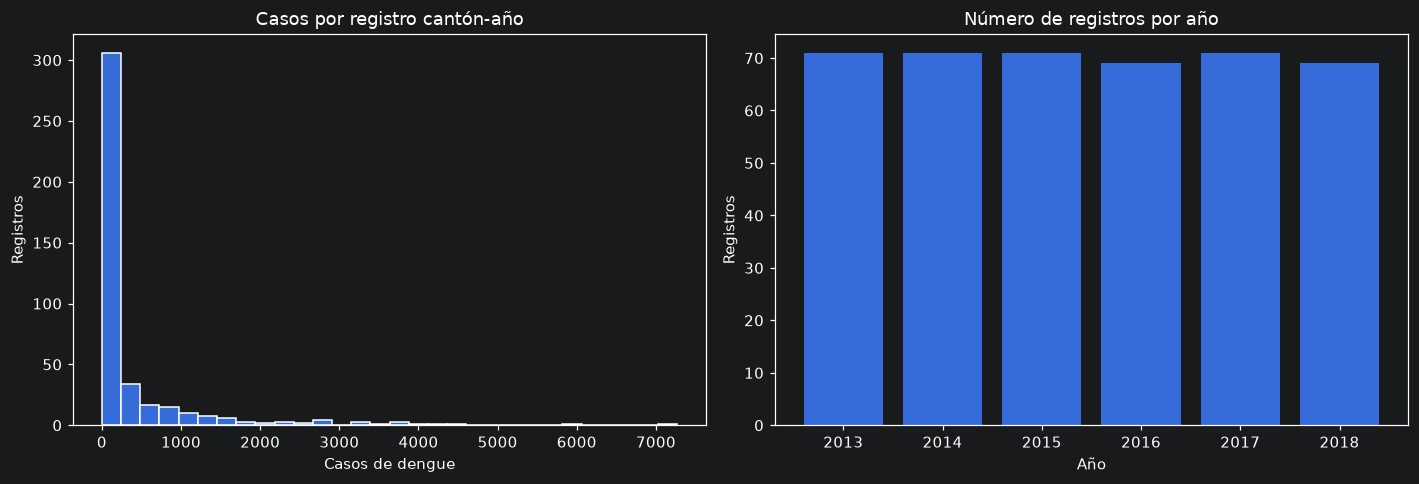

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].hist(datos["casos_dengue"].dropna(), bins=30, edgecolor="white")
ejes[0].set_title("Casos por registro cantón-año")
ejes[0].set_xlabel("Casos de dengue")
ejes[0].set_ylabel("Registros")
conteo_anios = datos["anio"].value_counts().sort_index()
ejes[1].bar(conteo_anios.index.astype(str), conteo_anios.values)
ejes[1].set_title("Número de registros por año")
ejes[1].set_xlabel("Año")
ejes[1].set_ylabel("Registros")
plt.tight_layout()
plt.show()

## 10. Detección de valores atípicos (IQR)

Se identifican casos fuera del rango intercuartílico. Los valores elevados podrían representar brotes reales; **no se eliminan automáticamente**.

Límite IQR inferior: -391.75
Límite IQR superior: 702.25
Registros fuera de límites IQR: 66


,anio,provincia,canton,casos_dengue
29,2013,Guanacaste,Nicoya,7272
30,2013,Guanacaste,Santa Cruz,5818
43,2013,Limón,Pococi,4504
44,2013,Limón,Siquirres,4304
277,2016,San José,Perez Zeledon,4096
66,2013,San José,Perez Zeledon,3784
1,2013,Alajuela,Atenas,3722
163,2015,Guanacaste,Abangares,3654
27,2013,Guanacaste,Liberia,3630
6,2013,Alajuela,Orotina,3304


C:\Users\andre\AppData\Local\Temp\ipykernel_18448\1913795325.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(serie_casos, vert=False)


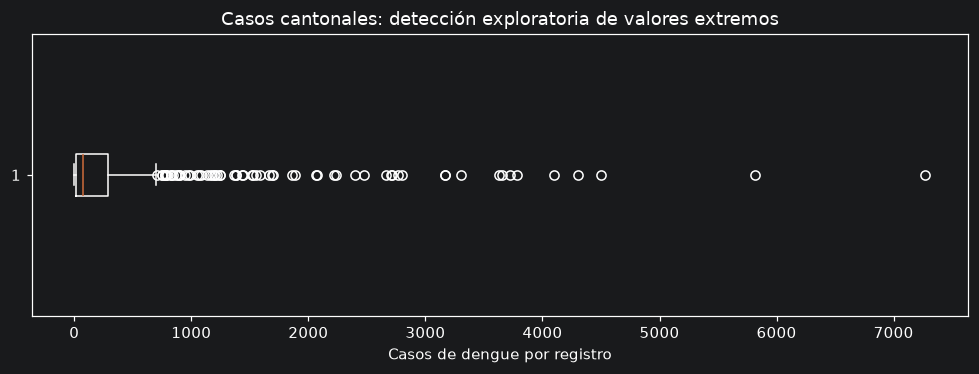

In [10]:
serie_casos = datos["casos_dengue"].dropna()
q1, q3 = serie_casos.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
atipicos = datos[(datos["casos_dengue"] < limite_inferior) | (datos["casos_dengue"] > limite_superior)]
print(f"Límite IQR inferior: {limite_inferior:.2f}")
print(f"Límite IQR superior: {limite_superior:.2f}")
print("Registros fuera de límites IQR:", len(atipicos))
display(atipicos.sort_values("casos_dengue", ascending=False).head(15))
plt.figure(figsize=(9, 3.5))
plt.boxplot(serie_casos, vert=False)
plt.title("Casos cantonales: detección exploratoria de valores extremos")
plt.xlabel("Casos de dengue por registro")
plt.tight_layout()
plt.show()

## 11. Validación de rangos y consistencia

Se comprueba que los casos sean números enteros no negativos y que los registros contengan provincia, cantón y años válidos.

In [11]:
casos_num = pd.to_numeric(datos["casos_dengue"], errors="coerce")
control_general = pd.DataFrame([
    ("Casos nulos o no numéricos", int(casos_num.isna().sum())),
    ("Casos negativos", int((casos_num < 0).sum())),
    ("Casos no enteros", int((casos_num.dropna() % 1 != 0).sum())),
    ("Años fuera de 2013–2018", int((~datos["anio"].between(2013, 2018)).sum())),
    ("Provincias vacías", int(datos["provincia"].fillna("").astype(str).str.strip().eq("").sum())),
    ("Cantones vacíos", int(datos["canton"].fillna("").astype(str).str.strip().eq("").sum())),
    ("Espacios extremos en provincias", int((datos["provincia"].fillna("") != datos["provincia"].fillna("").str.strip()).sum())),
    ("Espacios extremos en cantones", int((datos["canton"].fillna("") != datos["canton"].fillna("").str.strip()).sum())),
], columns=["Control", "Registros detectados"])
display(control_general)

,Control,Registros detectados
0,Casos nulos o no numéricos,0
1,Casos negativos,0
2,Casos no enteros,0
3,Años fuera de 2013–2018,0
4,Provincias vacías,0
5,Cantones vacíos,0
6,Espacios extremos en provincias,0
7,Espacios extremos en cantones,0


## 12. Visualización general del conjunto de datos

Se comparan los registros y las **sumas internas del archivo cantonal** por año. Esas sumas no son totales nacionales oficiales.

,anio,registros,cantones,provincias,suma_cantonal
0,2013,71,71,7,81942
1,2014,71,71,7,16742
2,2015,71,71,7,25852
3,2016,69,69,7,30700
4,2017,71,71,7,8340
5,2018,69,69,7,4530


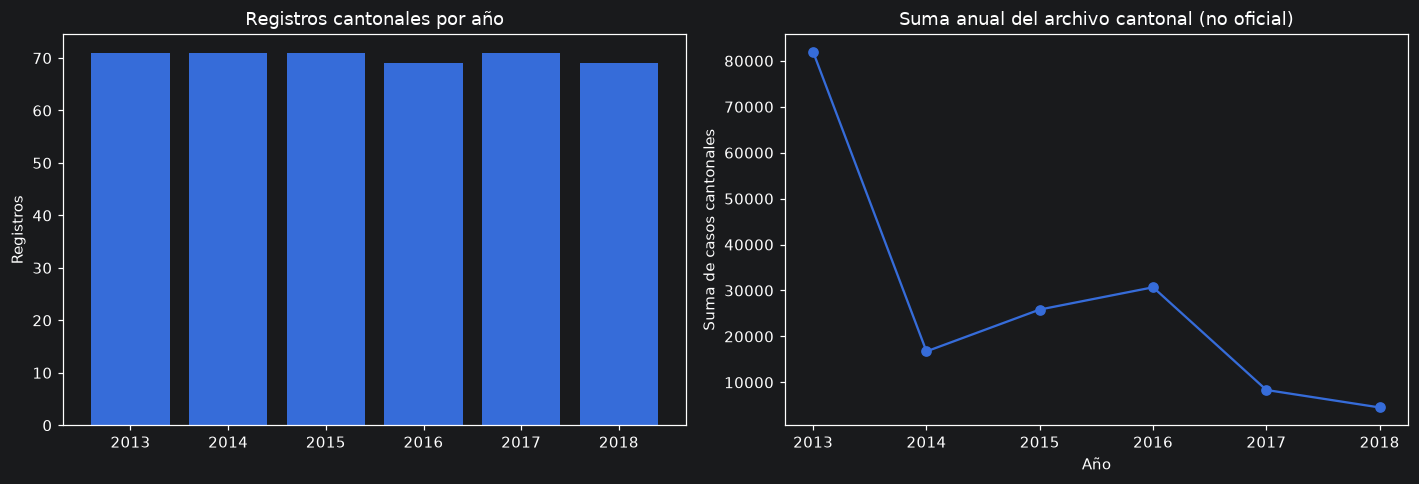

In [12]:
resumen_anual = datos.groupby("anio").agg(
    registros=("canton", "size"),
    cantones=("canton", "nunique"),
    provincias=("provincia", "nunique"),
    suma_cantonal=("casos_dengue", "sum")
).reset_index()
display(resumen_anual)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].bar(resumen_anual["anio"].astype(str), resumen_anual["registros"])
ejes[0].set_title("Registros cantonales por año")
ejes[0].set_ylabel("Registros")
ejes[1].plot(resumen_anual["anio"], resumen_anual["suma_cantonal"], marker="o")
ejes[1].set_title("Suma anual del archivo cantonal (no oficial)")
ejes[1].set_ylabel("Suma de casos cantonales")
ejes[1].set_xlabel("Año")
plt.tight_layout()
plt.show()

## 13. Distribución por categorías

Se revisa el número de registros de cada provincia y el número de cantones distintos asociados a ella.

,registros,cantones_distintos
provincia,,
San José,97,17
Alajuela,83,14
Guanacaste,66,11
Puntarenas,54,9
Heredia,54,9
Cartago,38,7
Limón,30,5


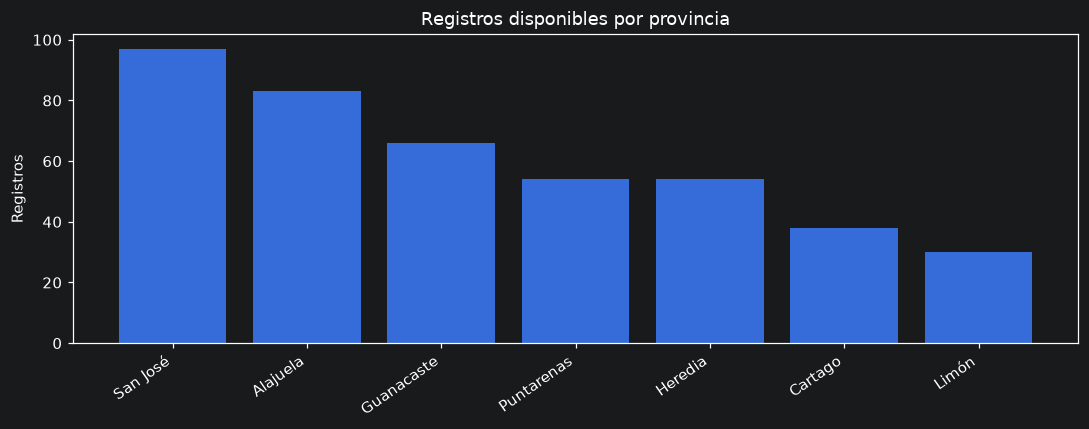

In [13]:
categoria_prov = datos.groupby("provincia").agg(
    registros=("canton", "size"),
    cantones_distintos=("canton", "nunique")
).sort_values("registros", ascending=False)
display(categoria_prov)
plt.figure(figsize=(10, 4))
plt.bar(categoria_prov.index, categoria_prov["registros"])
plt.title("Registros disponibles por provincia")
plt.ylabel("Registros")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 14. Frecuencia de ceros y casos elevados

Se diferencia explícitamente entre valores cero y cantones sin registro; un valor 0 representa una observación registrada, mientras que una combinación ausente no equivale a 0.

In [14]:
num_ceros = int((datos["casos_dengue"] == 0).sum())
print("Registros con cero casos:", num_ceros)
print(f"Porcentaje de registros con cero casos: {100 * num_ceros / len(datos):.2f} %")
print("Máximo de casos en un registro:", datos["casos_dengue"].max())
display(datos.nlargest(10, "casos_dengue")[["anio", "provincia", "canton", "casos_dengue"]])

Registros con cero casos: 21
Porcentaje de registros con cero casos: 4.98 %
Máximo de casos en un registro: 7272


,anio,provincia,canton,casos_dengue
29,2013,Guanacaste,Nicoya,7272
30,2013,Guanacaste,Santa Cruz,5818
43,2013,Limón,Pococi,4504
44,2013,Limón,Siquirres,4304
277,2016,San José,Perez Zeledon,4096
66,2013,San José,Perez Zeledon,3784
1,2013,Alajuela,Atenas,3722
163,2015,Guanacaste,Abangares,3654
27,2013,Guanacaste,Liberia,3630
6,2013,Alajuela,Orotina,3304


## 15. Cobertura temporal (2013–2018)

Se verifica qué años contiene el archivo y cuántos registros hay en cada uno.

In [15]:
anios_observados = sorted(datos["anio"].unique().tolist())
anios_esperados = set(range(2013, 2019))
print("Años presentes:", anios_observados)
print("Años faltantes respecto de 2013–2018:", sorted(anios_esperados - set(anios_observados)))
display(datos.groupby("anio").size().rename("Registros").to_frame())

Años presentes: [2013, 2014, 2015, 2016, 2017, 2018]
Años faltantes respecto de 2013–2018: []


,Registros
anio,
2013,71
2014,71
2015,71
2016,69
2017,71
2018,69


## 16. Cobertura de provincias y cantones por año

Se contabilizan los cantones y provincias distintos disponibles en cada año, identificando diferencias de cobertura.

In [16]:
cobertura = datos.groupby("anio").agg(
    provincias=("provincia", "nunique"),
    cantones=("canton", "nunique"),
    registros=("canton", "size")
)
display(cobertura)
print("Nombres de cantón distintos en todo el período:", datos["canton"].nunique())
print("Combinaciones provincia-cantón distintas:", datos[["provincia", "canton"]].drop_duplicates().shape[0])

,provincias,cantones,registros
anio,,,
2013,7,71,71
2014,7,71,71
2015,7,71,71
2016,7,69,69
2017,7,71,71
2018,7,69,69


Nombres de cantón distintos en todo el período: 72
Combinaciones provincia-cantón distintas: 72


## 17. Combinaciones provincia-cantón ausentes por año

Se comparan las combinaciones presentes en cada año contra la **unión de nombres observados en el propio archivo**. Esta comparación puede señalar ausencias o diferencias de escritura; no demuestra por sí sola falta de datos oficiales.

In [17]:
claves_observadas = set(map(tuple, datos[["provincia", "canton"]].drop_duplicates().values))
filas_ausentes = []
for anio in anios_observados:
    claves_anio = set(map(tuple, datos.loc[datos["anio"] == anio, ["provincia", "canton"]].values))
    for provincia, canton in sorted(claves_observadas - claves_anio):
        filas_ausentes.append({"Año": anio, "Provincia": provincia, "Cantón": canton})
df_ausentes = pd.DataFrame(filas_ausentes, columns=["Año", "Provincia", "Cantón"])
print("Combinaciones ausentes respecto al conjunto de nombres del archivo:", len(df_ausentes))
display(df_ausentes)

Combinaciones ausentes respecto al conjunto de nombres del archivo: 10


,Año,Provincia,Cantón
0,2013,San José,San Jose
1,2014,San José,San Jose
2,2015,San José,San Jose
3,2016,Cartago,Alvarado
4,2016,Cartago,Jimenez
5,2016,San José,San Jose
6,2017,San José,San Jose
7,2018,Alajuela,Alfaro Ruiz
8,2018,Cartago,Alvarado
9,2018,Cartago,Jimenez


## 18. Distribución de casos por cantón

Se resume la distribución de los casos por registro cantón-año e identifica su asimetría. Los valores son conteos, no tasas.

Estadísticas de casos por registro cantón-año:


,Casos
count,422.000000
mean,398.355450
std,849.645435
min,0.000000
25%,18.500000
50%,78.000000
75%,292.000000
max,7272.000000


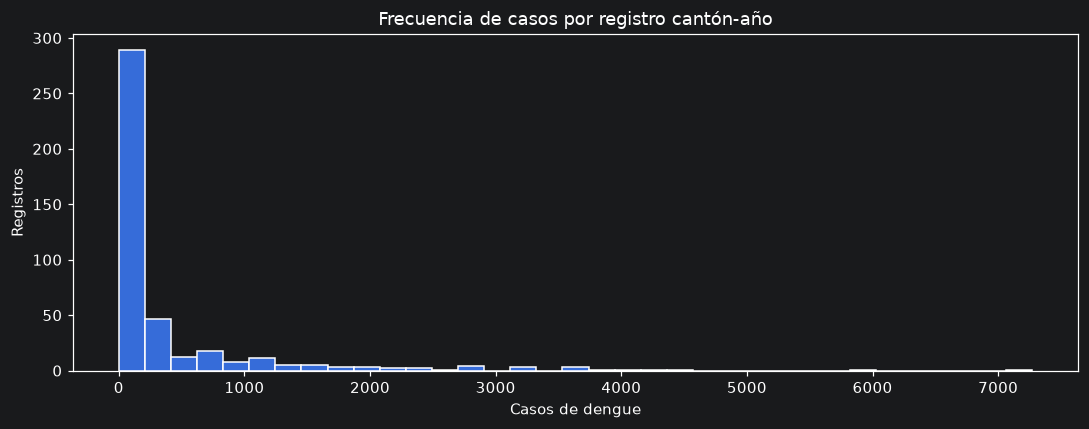

In [18]:
print("Estadísticas de casos por registro cantón-año:")
display(datos["casos_dengue"].describe().to_frame("Casos"))
plt.figure(figsize=(10, 4))
plt.hist(datos["casos_dengue"], bins=35, edgecolor="white")
plt.title("Frecuencia de casos por registro cantón-año")
plt.xlabel("Casos de dengue")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

## 19. Distribución agregada por provincia

Se suman los casos de los cantones asociados a cada provincia **dentro del mismo dataset**, exclusivamente para comparación relativa.

,provincia,Suma cantonal 2013–2018
2,Guanacaste,52554
5,Puntarenas,36702
4,Limón,25522
0,Alajuela,20758
6,San José,19364
3,Heredia,11118
1,Cartago,2088


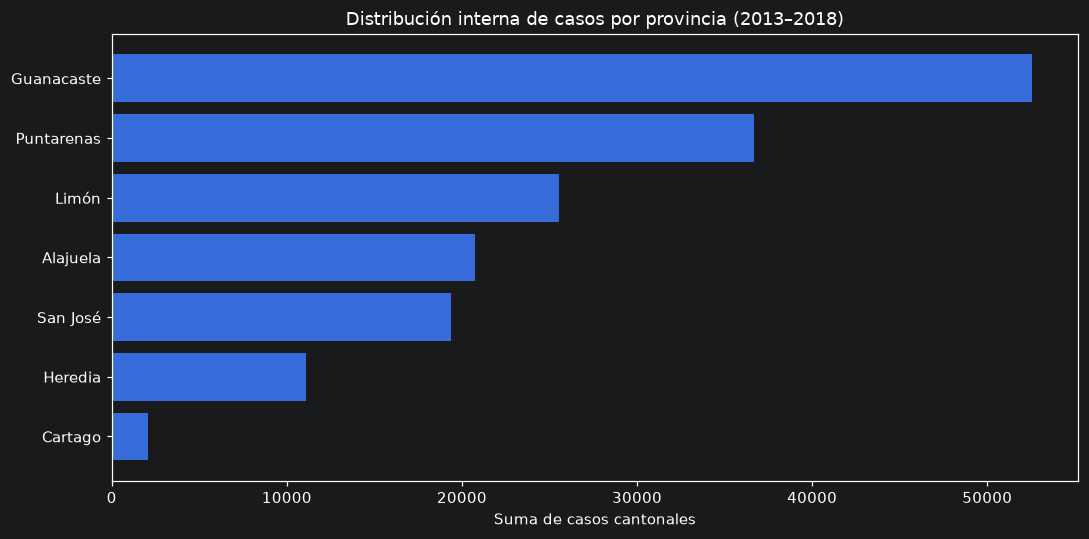

In [19]:
casos_provincia = datos.groupby("provincia", as_index=False)["casos_dengue"].sum().sort_values("casos_dengue", ascending=False)
display(casos_provincia.rename(columns={"casos_dengue": "Suma cantonal 2013–2018"}))
plt.figure(figsize=(10, 5))
plt.barh(casos_provincia["provincia"][::-1], casos_provincia["casos_dengue"][::-1])
plt.title("Distribución interna de casos por provincia (2013–2018)")
plt.xlabel("Suma de casos cantonales")
plt.tight_layout()
plt.show()

## 20. Ranking de cantones con mayor cantidad de casos

Se ordenan los cantones según la suma de sus registros entre 2013 y 2018. La comparación debe interpretarse con cautela porque no hay población cantonal ni necesariamente igual cobertura por año.

,provincia,canton,casos_acumulados,anios_con_registro
30,Guanacaste,Santa Cruz,12066,6
29,Guanacaste,Nicoya,11686,6
43,Limón,Pococi,9568,6
66,San José,Perez Zeledon,9014,6
1,Alajuela,Atenas,8020,6
40,Heredia,Sarapiqui,7076,6
44,Limón,Siquirres,6450,6
47,Puntarenas,Corredores,6188,6
51,Puntarenas,Golfito,5964,6
24,Guanacaste,Carrillo,5940,6


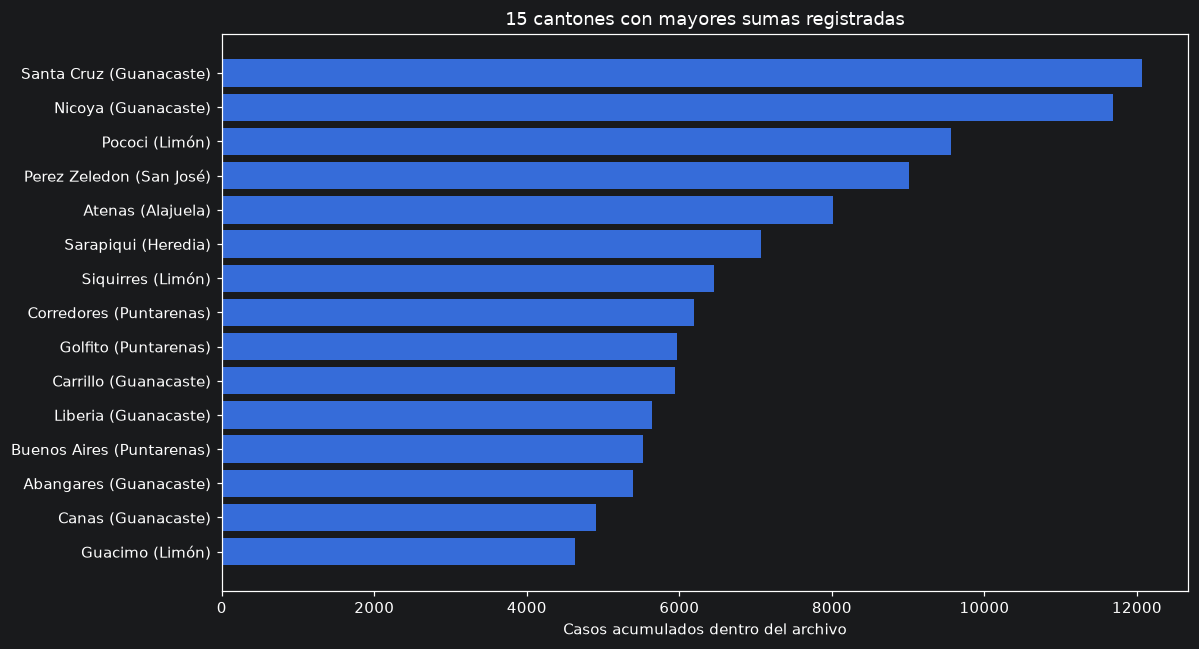

In [20]:
casos_cantones = (
    datos.groupby(["provincia", "canton"], as_index=False)
    .agg(casos_acumulados=("casos_dengue", "sum"), anios_con_registro=("anio", "nunique"))
    .sort_values("casos_acumulados", ascending=False)
)
mayores_cantones = casos_cantones.head(15)
display(mayores_cantones)
plt.figure(figsize=(11, 6))
etiquetas = (mayores_cantones["canton"] + " (" + mayores_cantones["provincia"] + ")").iloc[::-1]
plt.barh(etiquetas, mayores_cantones["casos_acumulados"].iloc[::-1])
plt.title("15 cantones con mayores sumas registradas")
plt.xlabel("Casos acumulados dentro del archivo")
plt.tight_layout()
plt.show()

## 21. Ranking de cantones con menor cantidad de casos

Se identifican los cantones con menores sumas en el período, sin confundir registros faltantes con cero casos.

,provincia,canton,casos_acumulados,anios_con_registro
16,Cartago,Jimenez,0,4
14,Cartago,Alvarado,0,4
0,Alajuela,Alfaro Ruiz,8,5
4,Alajuela,Los Chiles,22,6
15,Cartago,El Guarco,32,6
68,San José,San Jose,78,1
17,Cartago,La Union,100,6
19,Cartago,Paraiso,110,6
18,Cartago,Oreamuno,114,6
13,Alajuela,Valverde Vega,120,6


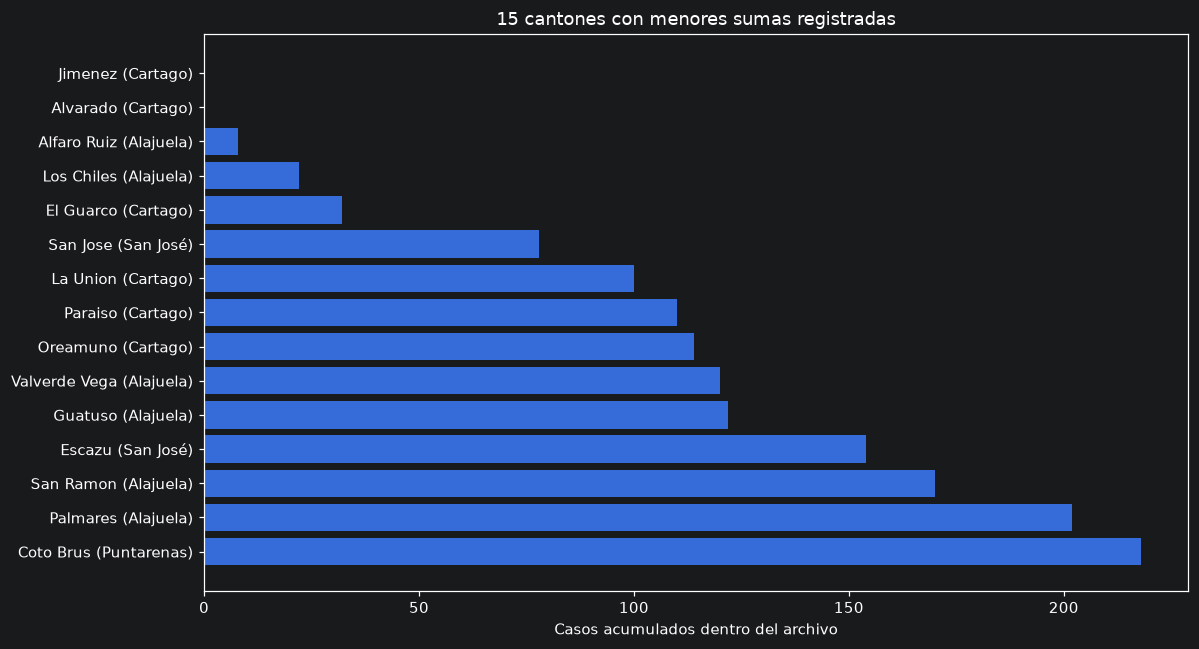

In [21]:
menores_cantones = casos_cantones.sort_values("casos_acumulados").head(15)
display(menores_cantones)
plt.figure(figsize=(11, 6))
etiquetas = (menores_cantones["canton"] + " (" + menores_cantones["provincia"] + ")").iloc[::-1]
plt.barh(etiquetas, menores_cantones["casos_acumulados"].iloc[::-1])
plt.title("15 cantones con menores sumas registradas")
plt.xlabel("Casos acumulados dentro del archivo")
plt.tight_layout()
plt.show()

## 22. Evolución anual de los cantones más destacados

Se comparan los casos año por año para los cantones con mayores sumas del período. Los años ausentes se conservan como valores faltantes.

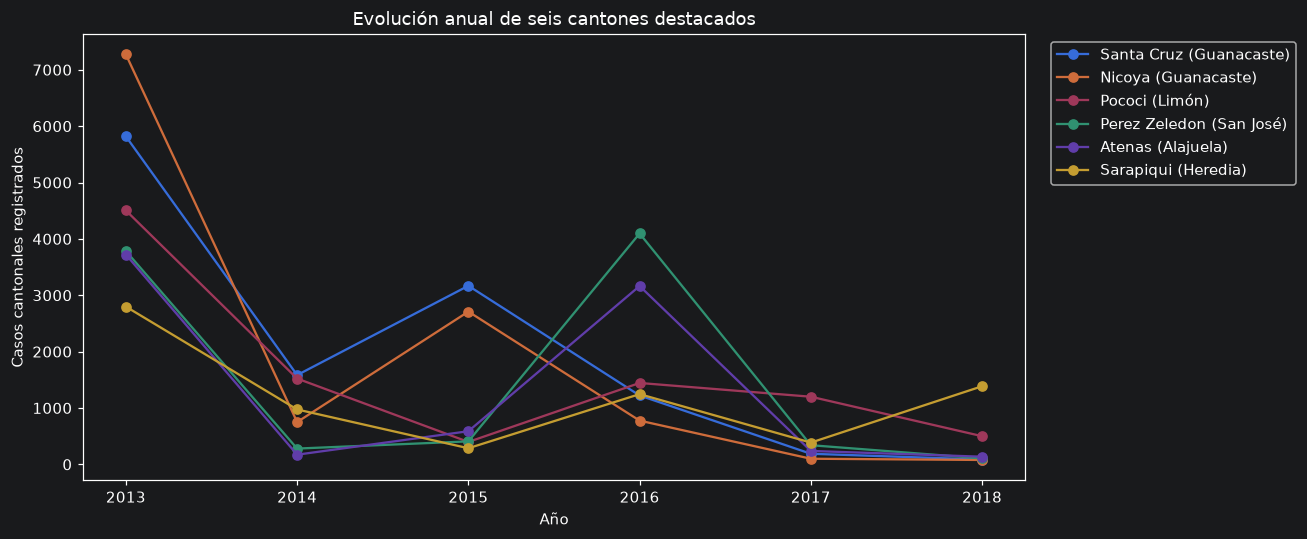

In [22]:
top_claves = list(casos_cantones.head(6)[["provincia", "canton"]].itertuples(index=False, name=None))
plt.figure(figsize=(12, 5))
for provincia, canton in top_claves:
    serie = datos[(datos["provincia"] == provincia) & (datos["canton"] == canton)].set_index("anio")["casos_dengue"]
    plt.plot(serie.index, serie.values, marker="o", label=f"{canton} ({provincia})")
plt.title("Evolución anual de seis cantones destacados")
plt.xlabel("Año")
plt.ylabel("Casos cantonales registrados")
plt.xticks(anios_observados)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 23. Comparación anual entre provincias

Se compara la distribución de casos agrupados por provincia en cada año, utilizando únicamente las sumas internas del dataset cantonal.

provincia,Alajuela,Cartago,Guanacaste,Heredia,Limón,Puntarenas,San José
anio,,,,,,,
2013,12010,1376,27554,4646,12880,15498,7978
2014,1116,172,4108,1538,3948,4654,1206
2015,1360,124,13902,616,670,7760,1420
2016,5282,126,5588,1988,2680,7480,7556
2017,672,158,794,770,4102,972,872
2018,318,132,608,1560,1242,338,332


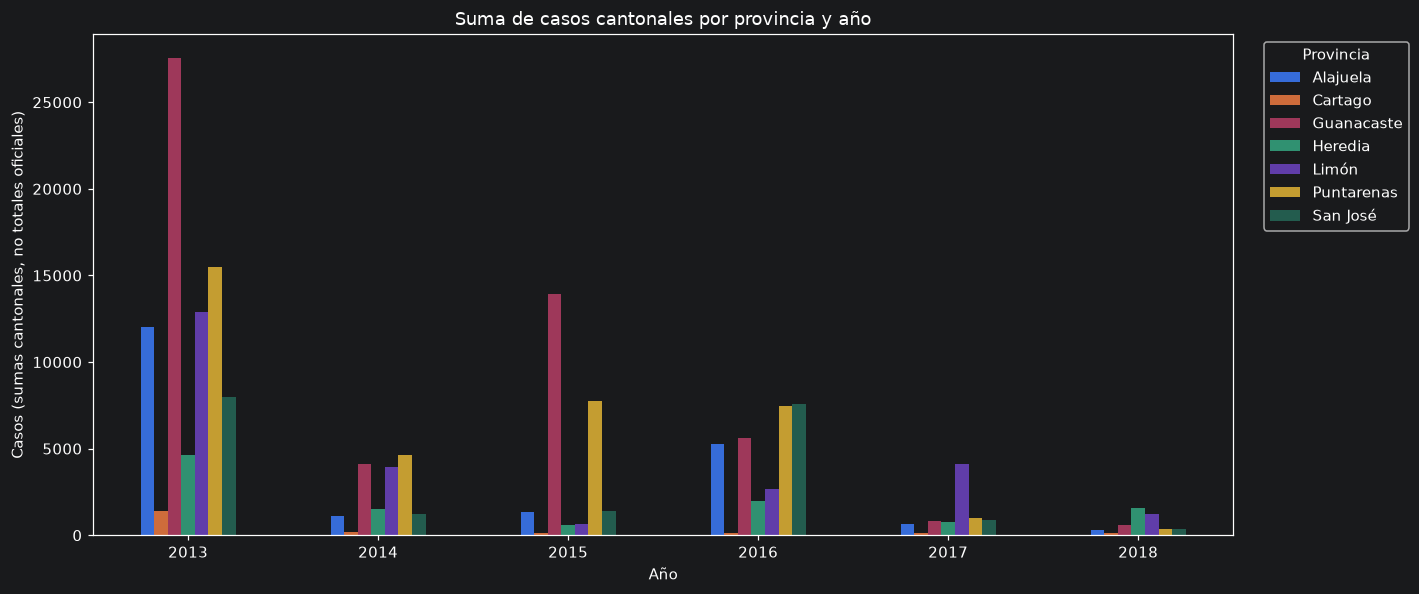

In [23]:
provincia_anual = datos.pivot_table(index="anio", columns="provincia", values="casos_dengue", aggfunc="sum")
display(provincia_anual)
provincia_anual.plot(kind="bar", figsize=(13, 5.5))
plt.title("Suma de casos cantonales por provincia y año")
plt.xlabel("Año")
plt.ylabel("Casos (sumas cantonales, no totales oficiales)")
plt.xticks(rotation=0)
plt.legend(title="Provincia", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 24. Participación porcentual de las provincias

Se calcula qué porcentaje de la suma cantonal registrada representa cada provincia en cada año. **Son proporciones internas del archivo, no tasas de enfermedad ni probabilidades de contagio.**

provincia,Alajuela,Cartago,Guanacaste,Heredia,Limón,Puntarenas,San José
anio,,,,,,,
2013,14.66,1.68,33.63,5.67,15.72,18.91,9.74
2014,6.67,1.03,24.54,9.19,23.58,27.80,7.20
2015,5.26,0.48,53.78,2.38,2.59,30.02,5.49
2016,17.21,0.41,18.20,6.48,8.73,24.36,24.61
2017,8.06,1.89,9.52,9.23,49.18,11.65,10.46
2018,7.02,2.91,13.42,34.44,27.42,7.46,7.33


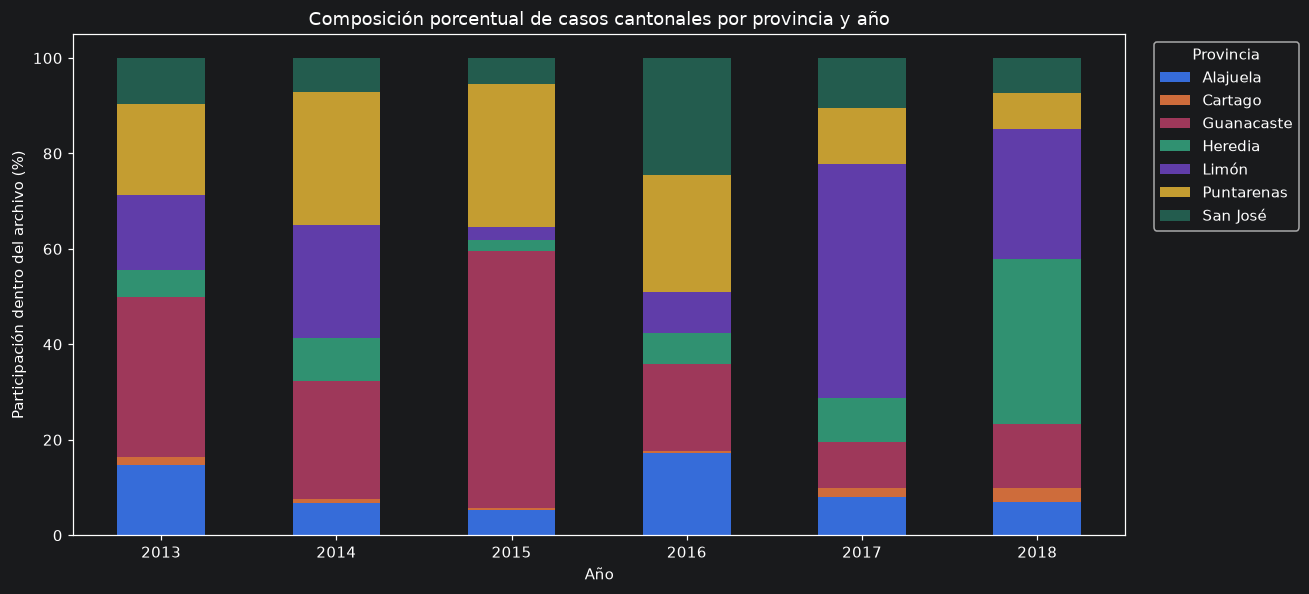

In [24]:
participacion_provincia = provincia_anual.div(provincia_anual.sum(axis=1), axis=0).mul(100)
display(participacion_provincia.round(2))
participacion_provincia.plot(kind="bar", stacked=True, figsize=(12, 5.5))
plt.title("Composición porcentual de casos cantonales por provincia y año")
plt.xlabel("Año")
plt.ylabel("Participación dentro del archivo (%)")
plt.xticks(rotation=0)
plt.legend(title="Provincia", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 25. Concentración de casos en los principales cantones

Se calcula qué proporción de las sumas cantonales de cada año corresponde a los cinco cantones con más casos de ese mismo año.

,Año,Suma cantonal,Casos de los cinco mayores,Participación de los cinco (%)
0,2013,81942,25682,31.34
1,2014,16742,7064,42.19
2,2015,25852,14000,54.15
3,2016,30700,11640,37.92
4,2017,8340,4398,52.73
5,2018,4530,2534,55.94


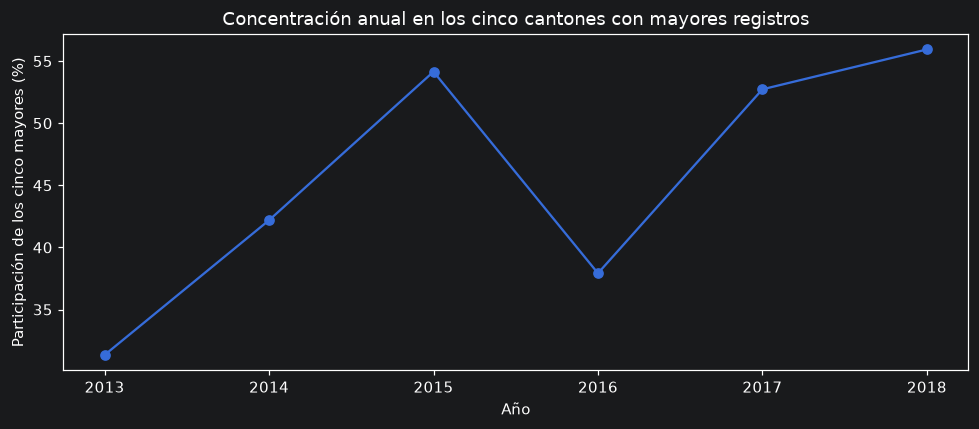

In [25]:
concentracion = []
for anio, grupo in datos.groupby("anio"):
    total = grupo["casos_dengue"].sum()
    cinco = grupo.nlargest(5, "casos_dengue")["casos_dengue"].sum()
    concentracion.append({
        "Año": int(anio), "Suma cantonal": int(total), "Casos de los cinco mayores": int(cinco),
        "Participación de los cinco (%)": round(100 * cinco / total, 2) if total else np.nan
    })
df_concentracion = pd.DataFrame(concentracion)
display(df_concentracion)
plt.figure(figsize=(9, 4))
plt.plot(df_concentracion["Año"], df_concentracion["Participación de los cinco (%)"], marker="o")
plt.title("Concentración anual en los cinco cantones con mayores registros")
plt.xlabel("Año")
plt.ylabel("Participación de los cinco mayores (%)")
plt.xticks(anios_observados)
plt.tight_layout()
plt.show()

## 26. Comparación entre sumas cantonales y serie nacional

Se comparan las sumas cantonales con el **archivo nacional real** del profesor para los años coincidentes (2014–2018). El README señala además que para 2013 la suma cantonal es 81.942 y el total nacional OPS es 49.993. Las diferencias pueden obedecer a definiciones distintas, por lo que no se deben reconciliar forzadamente.

In [26]:
archivo_nacional = ruta / "vectoria_dengue_nacional_real.csv"
nacional = pd.read_csv(archivo_nacional, usecols=["anio", "casos_dengue"])
suma_nacional_anual = nacional.groupby("anio")["casos_dengue"].sum()
suma_cantonal_anual = datos.groupby("anio")["casos_dengue"].sum()

comparacion = pd.DataFrame({
    "Suma cantonal": suma_cantonal_anual,
    "Serie nacional OPS (si disponible)": suma_nacional_anual
}).loc[anios_observados]
comparacion["Diferencia (cantonal - nacional)"] = (
    comparacion["Suma cantonal"] - comparacion["Serie nacional OPS (si disponible)"]
)
comparacion["Razón cantonal/nacional"] = (
    comparacion["Suma cantonal"] / comparacion["Serie nacional OPS (si disponible)"].replace(0, np.nan)
)
display(comparacion.round(2))
print("Referencia adicional del README para 2013: OPS nacional = 49.993; suma cantonal = 81.942.")
print("No interpretar las sumas cantonales como cifras nacionales oficiales.")

,Suma cantonal,Serie nacional OPS (si disponible),Diferencia (cantonal - nacional),Razón cantonal/nacional
anio,,,,
2013,81942.0,NaN,NaN,NaN
2014,16742.0,11049.0,5693.0,1.52
2015,25852.0,17485.0,8367.0,1.48
2016,30700.0,23319.0,7381.0,1.32
2017,8340.0,5561.0,2779.0,1.50
2018,4530.0,2735.0,1795.0,1.66


Referencia adicional del README para 2013: OPS nacional = 49.993; suma cantonal = 81.942.
No interpretar las sumas cantonales como cifras nacionales oficiales.


## 27. Revisión de nombres geográficos

Se preparan **claves auxiliares** sin tildes, con minúsculas y espacios normalizados para detectar variantes de escritura. **No se corrigen ni renombran los valores originales**: cualquier equivalencia debe revisarse con un catálogo oficial.

In [27]:
def normalizar_nombre(valor):
    texto = str(valor).strip().lower()
    texto = " ".join(texto.split())
    texto = "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))
    return texto

claves = datos[["provincia", "canton"]].drop_duplicates().copy()
claves["provincia_normalizada"] = claves["provincia"].map(normalizar_nombre)
claves["canton_normalizado"] = claves["canton"].map(normalizar_nombre)

variantes = (claves.groupby(["provincia_normalizada", "canton_normalizado"])
             .agg(nombres_originales=("canton", lambda s: sorted(s.unique())),
                  cantidad_variantes=("canton", "nunique"))
             .reset_index())
variantes = variantes[variantes["cantidad_variantes"] > 1]
print("Grupos de nombres equivalentes bajo normalización simple:", len(variantes))
display(variantes)
print("Catálogo de nombres (primeros 25):")
display(claves.sort_values(["provincia", "canton"]).head(25))

Grupos de nombres equivalentes bajo normalización simple: 0


,provincia_normalizada,canton_normalizado,nombres_originales,cantidad_variantes


Catálogo de nombres (primeros 25):


,provincia,canton,provincia_normalizada,canton_normalizado
0,Alajuela,Alfaro Ruiz,alajuela,alfaro ruiz
1,Alajuela,Atenas,alajuela,atenas
2,Alajuela,Grecia,alajuela,grecia
3,Alajuela,Guatuso,alajuela,guatuso
4,Alajuela,Los Chiles,alajuela,los chiles
5,Alajuela,Naranjo,alajuela,naranjo
6,Alajuela,Orotina,alajuela,orotina
7,Alajuela,Palmares,alajuela,palmares
8,Alajuela,Poas,alajuela,poas
9,Alajuela,San Carlos,alajuela,san carlos


## 28. Mapa de calor matricial: cantones por año

Se crea una **matriz de calor con Matplotlib** para explorar patrones entre los 20 cantones de mayores registros y los años. Este gráfico es una matriz, **no el mapa geográfico de Costa Rica**.

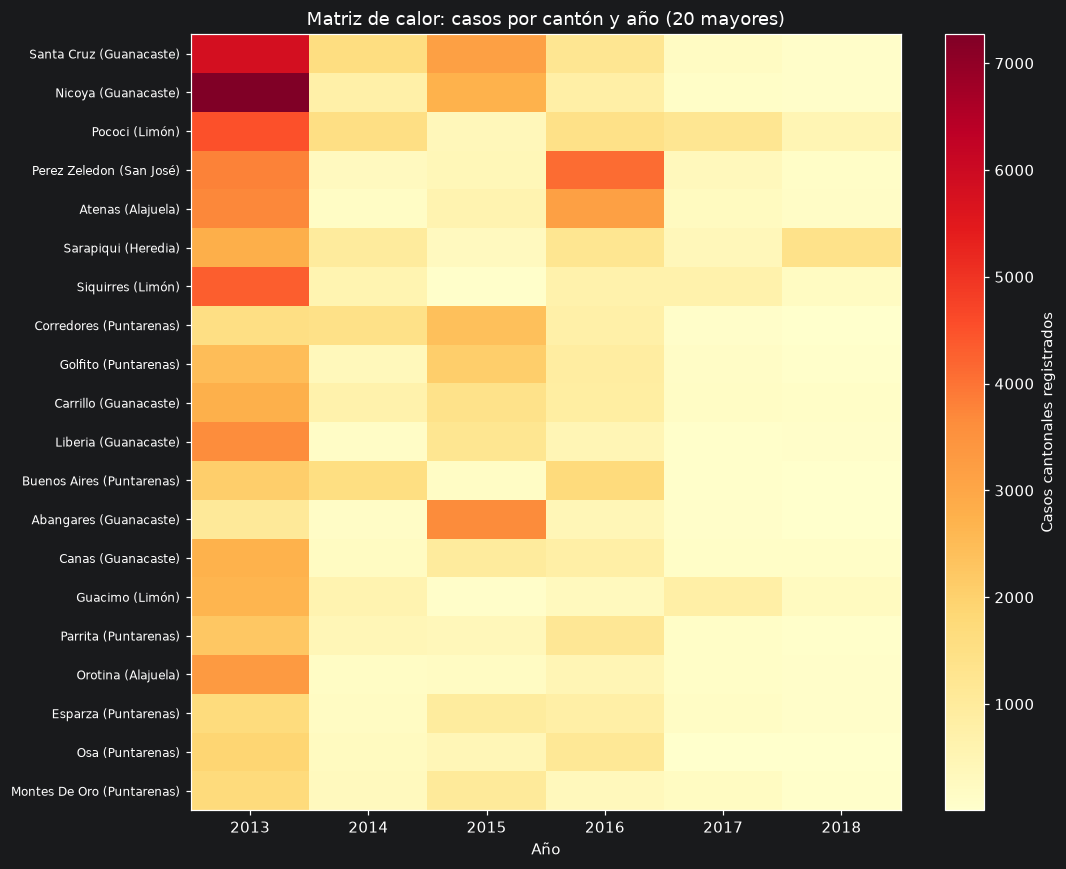

Las celdas faltantes indican combinaciones sin registro; no son necesariamente cero casos.


In [28]:
top20_claves = casos_cantones.head(20)[["provincia", "canton"]]
base_top20 = datos.merge(top20_claves, on=["provincia", "canton"], how="inner").copy()
base_top20["Ubicación"] = base_top20["canton"] + " (" + base_top20["provincia"] + ")"
matriz_calor = base_top20.pivot_table(index="Ubicación", columns="anio", values="casos_dengue", aggfunc="sum")
orden = (top20_claves["canton"] + " (" + top20_claves["provincia"] + ")").tolist()
matriz_calor = matriz_calor.reindex(index=orden, columns=anios_observados)

fig, eje = plt.subplots(figsize=(10, 8))
imagen = eje.imshow(matriz_calor.values, aspect="auto", cmap="YlOrRd", interpolation="nearest")
eje.set_yticks(range(len(matriz_calor.index)))
eje.set_yticklabels(matriz_calor.index, fontsize=8)
eje.set_xticks(range(len(anios_observados)))
eje.set_xticklabels(anios_observados)
eje.set_title("Matriz de calor: casos por cantón y año (20 mayores)")
eje.set_xlabel("Año")
fig.colorbar(imagen, ax=eje, label="Casos cantonales registrados")
plt.tight_layout()
plt.show()
print("Las celdas faltantes indican combinaciones sin registro; no son necesariamente cero casos.")

## 29. Tabla preparada para el mapa de calor geográfico

Se prepara una tabla de casos y **participación relativa** para el último año disponible. Para dibujar un mapa cantonal real se requiere además un GeoJSON o shapefile de límites cantonales y verificar las correspondencias de nombres o códigos geográficos.

In [29]:
anio_mapa = int(datos["anio"].max())
mapa_tabla = datos.loc[datos["anio"] == anio_mapa, ["anio", "provincia", "canton", "casos_dengue"]].copy()
suma_anio = mapa_tabla["casos_dengue"].sum()
mapa_tabla["porcentaje_del_anio"] = (100 * mapa_tabla["casos_dengue"] / suma_anio).round(2) if suma_anio else np.nan
mapa_tabla["provincia_clave"] = mapa_tabla["provincia"].map(normalizar_nombre)
mapa_tabla["canton_clave"] = mapa_tabla["canton"].map(normalizar_nombre)
mapa_tabla = mapa_tabla.sort_values("casos_dengue", ascending=False).reset_index(drop=True)
print("Año preparado para el mapa:", anio_mapa)
print("Cantones con registro:", len(mapa_tabla))
display(mapa_tabla.head(20))
print("Pendiente para la app: conseguir límites cantonales y validar correspondencias geográficas.")

Año preparado para el mapa: 2018
Cantones con registro: 69


,anio,provincia,canton,casos_dengue,porcentaje_del_anio,provincia_clave,canton_clave
0,2018,Heredia,Sarapiqui,1386,30.60,heredia,sarapiqui
1,2018,Limón,Pococi,500,11.04,limon,pococi
2,2018,Limón,Guacimo,242,5.34,limon,guacimo
3,2018,Limón,Siquirres,218,4.81,limon,siquirres
4,2018,Limón,Talamanca,188,4.15,limon,talamanca
5,2018,Alajuela,Atenas,136,3.00,alajuela,atenas
6,2018,Guanacaste,Canas,118,2.60,guanacaste,canas
7,2018,Guanacaste,Carrillo,110,2.43,guanacaste,carrillo
8,2018,San José,Perez Zeledon,106,2.34,san jose,perez zeledon
9,2018,Limón,Matina,94,2.08,limon,matina


Pendiente para la app: conseguir límites cantonales y validar correspondencias geográficas.


## 30. Requisitos de calidad para integrar un mapa geográfico

Se revisan condiciones que pueden afectar el emparejamiento entre el CSV y una futura capa geográfica (GeoJSON/shapefile). El archivo actual no contiene coordenadas ni geometrías.

In [30]:
control_mapa = pd.DataFrame([
    ("Años disponibles", len(anios_observados)),
    ("Provincias distintas", int(datos["provincia"].nunique())),
    ("Nombres cantón distintos (todos los años)", int(datos["canton"].nunique())),
    ("Pares provincia-cantón distintos", int(datos[["provincia", "canton"]].drop_duplicates().shape[0])),
    ("Combinaciones ausentes vs. unión observada", len(df_ausentes)),
    ("Claves año-provincia-cantón repetidas", duplicados_clave),
    ("Registros con cero casos (no ausentes)", num_ceros),
    ("Datos de población cantonal en este CSV", int("poblacion" in datos.columns)),
    ("Geometrías en este CSV", int(any(c in datos.columns for c in ["geometry", "lat", "lon", "codigo_canton"]))),
], columns=["Indicador", "Valor"])
display(control_mapa)
print("El mapa geográfico necesita límites de cantones y una correspondencia validada con el CSV.")
print("El mapa representará distribución histórica, no predicciones semanales de la LSTM.")

,Indicador,Valor
0,Años disponibles,6
1,Provincias distintas,7
2,Nombres cantón distintos (todos los años),72
3,Pares provincia-cantón distintos,72
4,Combinaciones ausentes vs. unión observada,10
5,Claves año-provincia-cantón repetidas,0
6,Registros con cero casos (no ausentes),21
7,Datos de población cantonal en este CSV,0
8,Geometrías en este CSV,0


El mapa geográfico necesita límites de cantones y una correspondencia validada con el CSV.
El mapa representará distribución histórica, no predicciones semanales de la LSTM.


## 31. Resumen automático de resultados del EDA

Se consolidan los indicadores calculados durante el análisis. Estos resultados sirven como base para redactar manualmente las conclusiones.

In [31]:
print("=" * 65)
print("RESUMEN AUTOMÁTICO — EDA CANTONAL, VECTORIA")
print("=" * 65)

indicadores = [
    ("Registros analizados", len(datos)),
    ("Columnas", datos.shape[1]),
    ("Años disponibles", len(anios_observados)),
    ("Primer año", min(anios_observados)),
    ("Último año", max(anios_observados)),
    ("Provincias", datos["provincia"].nunique()),
    ("Nombres distintos de cantón", datos["canton"].nunique()),
    ("Combinaciones distintas provincia-cantón", len(claves)),
    ("Registros con valores faltantes", int(datos.isna().any(axis=1).sum())),
    ("Filas duplicadas exactas", duplicados_exactos),
    ("Claves año-provincia-cantón duplicadas", duplicados_clave),
    ("Registros con cero casos", num_ceros),
    ("Registros fuera de límites IQR", len(atipicos)),
    ("Casos máximos en un cantón-año", int(datos["casos_dengue"].max())),
    ("Combinaciones ausentes vs. unión observada", len(df_ausentes)),
    ("Grupos de escritura equivalente detectados", len(variantes)),
    ("Provincias presentes el último año", datos.loc[datos["anio"] == max(anios_observados), "provincia"].nunique()),
    ("Cantones con registro el último año", len(mapa_tabla)),
]
resumen_eda = pd.DataFrame(indicadores, columns=["Indicador", "Resultado"])
display(resumen_eda)

print("\nCOBERTURA ANUAL")
display(cobertura)
print("\nSUMAS CANTONALES Y COMPARACIÓN CON SERIE NACIONAL")
display(comparacion.round(2))
print("\nRANKING: 10 CANTONES CON MAYORES SUMAS EN EL PERÍODO")
display(casos_cantones.head(10))
print("\nRANKING: 10 CANTONES CON MENORES SUMAS EN EL PERÍODO")
display(casos_cantones.sort_values("casos_acumulados").head(10))
print("\nCONTROLES PARA MAPA")
display(control_mapa)
print("\nAviso: los totales de cantones NO son totales nacionales oficiales.")

RESUMEN AUTOMÁTICO — EDA CANTONAL, VECTORIA


,Indicador,Resultado
0,Registros analizados,422
1,Columnas,4
2,Años disponibles,6
3,Primer año,2013
4,Último año,2018
5,Provincias,7
6,Nombres distintos de cantón,72
7,Combinaciones distintas provincia-cantón,72
8,Registros con valores faltantes,0
9,Filas duplicadas exactas,0



COBERTURA ANUAL


,provincias,cantones,registros
anio,,,
2013,7,71,71
2014,7,71,71
2015,7,71,71
2016,7,69,69
2017,7,71,71
2018,7,69,69



SUMAS CANTONALES Y COMPARACIÓN CON SERIE NACIONAL


,Suma cantonal,Serie nacional OPS (si disponible),Diferencia (cantonal - nacional),Razón cantonal/nacional
anio,,,,
2013,81942.0,NaN,NaN,NaN
2014,16742.0,11049.0,5693.0,1.52
2015,25852.0,17485.0,8367.0,1.48
2016,30700.0,23319.0,7381.0,1.32
2017,8340.0,5561.0,2779.0,1.50
2018,4530.0,2735.0,1795.0,1.66


... (3 outputs left out)

,provincia,canton,casos_acumulados,anios_con_registro
16,Cartago,Jimenez,0,4
14,Cartago,Alvarado,0,4
0,Alajuela,Alfaro Ruiz,8,5
4,Alajuela,Los Chiles,22,6
15,Cartago,El Guarco,32,6
68,San José,San Jose,78,1
17,Cartago,La Union,100,6
19,Cartago,Paraiso,110,6
18,Cartago,Oreamuno,114,6
13,Alajuela,Valverde Vega,120,6



CONTROLES PARA MAPA


,Indicador,Valor
0,Años disponibles,6
1,Provincias distintas,7
2,Nombres cantón distintos (todos los años),72
3,Pares provincia-cantón distintos,72
4,Combinaciones ausentes vs. unión observada,10
5,Claves año-provincia-cantón repetidas,0
6,Registros con cero casos (no ausentes),21
7,Datos de población cantonal en este CSV,0
8,Geometrías en este CSV,0



Aviso: los totales de cantones NO son totales nacionales oficiales.



## 32. Conclusiones generales del EDA

El análisis exploratorio del dataset `vectoria_casos_cantonal_anual_real.csv` permitió estudiar la distribución histórica de los casos de dengue por cantón y provincia de Costa Rica durante el período 2013–2018.

Se evaluaron la calidad de los registros, su cobertura territorial, la evolución anual de los casos, las diferencias entre cantones y las inconsistencias presentes en la información.

El objetivo principal fue identificar las características y limitaciones del dataset antes de utilizarlo para desarrollar el mapa de calor del proyecto VectorIA.

### 32.1. Principales hallazgos

1. **Cantidad de registros:** se analizaron 422 registros distribuidos en cuatro columnas, correspondientes a seis años, desde 2013 hasta 2018.

2. **Cobertura geográfica:** el dataset incluye las siete provincias de Costa Rica y 72 combinaciones diferentes de provincia-cantón. Aunque el documento del profesor menciona 71 cantones, el análisis identificó 72, por lo que esta diferencia debe investigarse.

3. **Calidad de los datos:** no se encontraron valores faltantes, filas exactamente duplicadas ni combinaciones repetidas de año, provincia y cantón. Esto representa una ventaja para la exploración de los registros.

4. **Cobertura temporal:** la cantidad de cantones registrados no es idéntica todos los años:
   - 2013: 71 registros.
   - 2014: 71 registros.
   - 2015: 71 registros.
   - 2016: 69 registros.
   - 2017: 71 registros.
   - 2018: 69 registros.

5. **Combinaciones ausentes:** se identificaron 10 combinaciones de cantón-año ausentes respecto a las 72 combinaciones territoriales observadas en el conjunto completo. Esto demuestra que la cobertura temporal no es totalmente uniforme.

6. **Registros con cero casos:** se identificaron 21 registros con cero casos de dengue. Estos valores deben distinguirse de los registros ausentes, ya que un cero representa una cantidad registrada, mientras que una ausencia indica falta de información para esa combinación.

7. **Distribución de casos:** la frecuencia de casos por cantón-año presenta una distribución asimétrica hacia la derecha. La mayoría de los registros contiene cantidades relativamente bajas, mientras que un grupo reducido presenta valores considerablemente elevados.

8. **Valores atípicos:** mediante el método del rango intercuartílico (IQR), se identificaron 66 registros fuera de los límites estadísticos habituales. Estos valores no deben eliminarse automáticamente, ya que podrían representar diferencias epidemiológicas reales entre cantones y años.

9. **Valor máximo:** el mayor registro individual fue de 7.272 casos en una combinación de cantón y año, mostrando la existencia de concentraciones elevadas de casos en determinados períodos.

10. **Evolución anual:** los gráficos muestran variaciones importantes entre los años analizados. El archivo presenta su mayor suma cantonal en 2013, seguida de una disminución considerable en 2014. Posteriormente, se observan incrementos en 2015 y 2016, seguidos de nuevas reducciones en 2017 y 2018.

11. **Distribución provincial:** Guanacaste presenta la mayor suma acumulada de casos dentro del archivo durante 2013–2018, seguida por Puntarenas y Limón. Cartago presenta la menor suma acumulada.

12. **Cantones con mayores acumulados:** los principales cantones identificados fueron:
    - Santa Cruz (Guanacaste): 12.066 casos.
    - Nicoya (Guanacaste): 11.686 casos.
    - Pococí (Limón): 9.568 casos.
    - Pérez Zeledón (San José): 9.014 casos.
    - Atenas (Alajuela): 8.020 casos.

    Estos valores corresponden a sumas de registros del dataset y deben interpretarse considerando sus limitaciones de comparabilidad.

13. **Cantones con menores acumulados:** entre los registros con cantidades más bajas destacan Jiménez y Alvarado, ambos de Cartago, con acumulados de cero casos durante los cuatro años en los que aparecen registrados.

14. **Comparabilidad entre cantones:** algunos cantones cuentan con menos años de información que otros. Por ejemplo, San José aparece con un solo año registrado en la tabla de menores acumulados. Por esta razón, los rankings acumulados pueden favorecer o perjudicar a determinados cantones según su cobertura temporal.

15. **Evolución de cantones destacados:** los gráficos muestran que Santa Cruz, Nicoya, Pococí, Pérez Zeledón, Atenas y Sarapiquí presentan variaciones considerables entre años. Algunos registraron sus valores más elevados durante 2013, mientras que otros presentaron incrementos importantes en 2015 o 2016.

16. **Concentración territorial:** la participación de los cinco cantones con mayores registros anuales varía aproximadamente entre el 31 % y el 56 % del total del archivo correspondiente a cada año. Esto evidencia que una parte importante de los casos se concentra en un número reducido de cantones.

17. **Composición provincial:** los porcentajes por provincia cambian considerablemente entre 2013 y 2018. Esto demuestra que la distribución territorial de los casos no es constante y que diferentes provincias presentan mayor participación según el año.

18. **Mapa de calor exploratorio:** la matriz de casos por cantón y año permitió visualizar las diferencias territoriales y temporales. Destacan los valores elevados de Santa Cruz y Nicoya en 2013, así como otros incrementos localizados durante 2015 y 2016.

19. **Consistencia de nombres:** el análisis automático no detectó grupos de escritura equivalente. Sin embargo, será necesario revisar la correspondencia de los nombres cantonales con la fuente geográfica que se utilice para construir el mapa.

20. **Diferencia entre totales cantonales y nacionales:** según la documentación del profesor, las sumas del archivo cantonal no coinciden necesariamente con los totales nacionales de OPS/PAHO. Por ejemplo, en 2013 la suma cantonal alcanza 81.942 casos, mientras que el total nacional indicado es de 49.993.

    Esta discrepancia representa una limitación importante de calidad y comparabilidad. El documento sugiere que podría existir una diferencia en la definición de caso utilizada por las fuentes, aunque no establece una causa definitiva.

21. **Ausencia de población cantonal:** el dataset no incluye información de población por cantón. Por lo tanto, no permite calcular directamente tasas de incidencia por cada 100.000 habitantes.

22. **Ausencia de información geográfica:** el CSV tampoco contiene polígonos, coordenadas ni geometrías de los cantones. Por ello, será necesario incorporar una fuente geográfica adicional para representar correctamente los territorios en el mapa de calor.

23. **Independencia de la LSTM:** este dataset contiene registros históricos anuales por cantón y no incorpora las predicciones semanales del modelo LSTM. Su función principal es la visualización territorial histórica, no el pronóstico de casos futuros.

### 32.2. Recomendaciones para el mapa de calor

- **Verificar los cantones:** investigar la diferencia entre los 72 cantones identificados en el análisis y los 71 mencionados en la documentación del profesor.

- **Revisar la cobertura temporal:** identificar las 10 combinaciones de cantón-año ausentes antes de preparar las visualizaciones.

- **Diferenciar ceros y ausencias:** no representar automáticamente los cantones sin registro como territorios con cero casos.

- **Conservar valores extremos:** revisar los 66 registros atípicos antes de decidir cualquier tratamiento, considerando que podrían representar concentraciones reales de dengue.

- **Utilizar proporciones y rankings:** seguir la recomendación del profesor de utilizar las cifras cantonales principalmente para comparaciones relativas dentro del archivo, evitando presentarlas como totales nacionales oficiales.

- **Advertir sobre las inconsistencias:** incluir una aclaración visible sobre las diferencias entre las sumas cantonales y los registros nacionales.

- **Incorporar datos geográficos:** obtener un archivo GeoJSON o Shapefile con los límites cantonales de Costa Rica para construir el mapa interactivo.

- **Estandarizar nombres:** verificar que los nombres de provincias y cantones coincidan con los identificadores utilizados en el archivo geográfico.

- **Permitir seleccionar el año:** implementar un selector de 2013 a 2018 para que el usuario pueda explorar la distribución histórica correspondiente a cada período.

- **Mostrar información por cantón:** permitir consultar el nombre del cantón, provincia, año y cantidad registrada de casos.

- **Considerar la cobertura de los datos:** indicar cuándo un cantón no tenga información disponible para el año seleccionado.

- **Evitar interpretaciones incorrectas:** no afirmar que los cantones con más casos registrados necesariamente presentan mayor riesgo individual, debido a las diferencias de población y las limitaciones del dataset.

- **Evaluar tasas de incidencia:** si posteriormente se obtiene información poblacional confiable, considerar el cálculo de casos por cada 100.000 habitantes para mejorar las comparaciones territoriales.

- **Mantener separado el mapa histórico:** no utilizar las predicciones nacionales de la LSTM como si fueran estimaciones cantonales, ya que el modelo no proporciona esa distribución geográfica.

### 32.3. Conclusión final

El dataset `vectoria_casos_cantonal_anual_real.csv` proporciona información útil para estudiar la distribución histórica del dengue en los cantones de Costa Rica durante el período 2013–2018.

El análisis permitió examinar 422 registros correspondientes a las siete provincias del país, identificando variaciones importantes entre cantones y años. Aunque no se encontraron valores faltantes dentro de los registros existentes ni duplicados exactos, se identificaron 10 combinaciones territoriales y temporales ausentes, lo que evidencia diferencias en la cobertura del dataset.

Uno de los hallazgos principales fue la distribución desigual de los casos entre cantones. Guanacaste presentó la mayor suma acumulada del archivo, destacando Santa Cruz y Nicoya entre los cantones con mayores registros. Por otra parte, Cartago presentó una participación considerablemente menor.

También se identificaron 66 valores atípicos mediante el método IQR. Estos resultados reflejan una distribución con numerosos registros bajos y algunos valores elevados, por lo que deben examinarse considerando el contexto territorial y temporal antes de aplicar cualquier tratamiento estadístico.

Los gráficos de evolución anual mostraron que la distribución de casos cambia considerablemente entre años, tanto a nivel cantonal como provincial. La concentración de una parte importante de los registros en pocos cantones refuerza la utilidad de representar esta información mediante un mapa de calor.

Sin embargo, el análisis identificó limitaciones que deben considerarse antes de implementar la visualización definitiva.

La principal es la inconsistencia entre las sumas cantonales y los totales nacionales indicados por OPS/PAHO. Esto impide interpretar directamente la suma del archivo cantonal como una cifra nacional oficial y exige utilizar los registros con precaución, principalmente para estudiar proporciones y distribuciones relativas.

Otra limitación es la ausencia de población cantonal y geometrías geográficas. Sin estos elementos, no es posible calcular directamente tasas de incidencia ni generar un mapa geográfico completo utilizando exclusivamente el CSV proporcionado.

Finalmente, se identificó una diferencia entre la cantidad de cantones mencionada en el documento del profesor y la cantidad de combinaciones territoriales encontradas durante el EDA. Esta situación deberá revisarse antes de vincular los registros con los límites geográficos.

En conclusión, el dataset es adecuado como base para desarrollar una visualización histórica de la distribución territorial del dengue en VectorIA, siempre que se respeten sus limitaciones de cobertura, comparabilidad y calidad de los datos.

Se recomienda implementar el mapa de calor utilizando proporciones, rankings y comparaciones anuales, incorporando información geográfica adicional y aclaraciones sobre la procedencia e interpretación de las cifras.

Este módulo permitirá complementar las predicciones nacionales de la LSTM con información histórica territorial, sin presentar los datos cantonales como predicciones futuras.
